In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Run the following commands for generating the data of Figure 6.

```bash
python simulations/code_capacity/logical_error_rate_gsm.py --distances 5 7 --error-rates 0.175 0.226 0.005 --shots 50000 --no-post-processing --output simulations/code_capacity/Fig-6-threshold/data/gsm/d05_07.csv
python simulations/code_capacity/logical_error_rate_gsm.py --distances 13 15 --error-rates 0.225 0.276 0.005 --shots 50000 --no-post-processing --output simulations/code_capacity/Fig-6-threshold/data/gsm/d13_15.csv
python simulations/code_capacity/logical_error_rate_gsm.py --distances 21 23 --error-rates 0.255 0.306 0.005 --shots 50000 --no-post-processing --output simulations/code_capacity/Fig-6-threshold/data/gsm/d21_23.csv
python simulations/code_capacity/logical_error_rate_gsm.py --distances 29 31 --error-rates 0.255 0.306 0.005 --shots 50000 --no-post-processing --output simulations/code_capacity/Fig-6-threshold/data/gsm/d29_31.csv
python simulations/code_capacity/logical_error_rate_gsm.py --distances 37 39 --error-rates 0.27 0.321 0.005 --shots 50000 --no-post-processing --output simulations/code_capacity/Fig-6-threshold/data/gsm/d37_39.csv
python simulations/code_capacity/logical_error_rate_gsm.py --distances 45 47 --error-rates 0.28 0.331 0.005 --shots 50000 --no-post-processing --output simulations/code_capacity/Fig-6-threshold/data/gsm/d45_47.csv

python simulations/code_capacity/logical_error_rate_gsm.py --distances 5 7 --error-rates 0.235 0.286 0.005 --shots 50000 --output simulations/code_capacity/Fig-6-threshold/data/gsm_pp/d05_07.csv
python simulations/code_capacity/logical_error_rate_gsm.py --distances 13 15 --error-rates 0.315 0.366 0.005 --shots 50000 --output simulations/code_capacity/Fig-6-threshold/data/gsm_pp/d13_15.csv
python simulations/code_capacity/logical_error_rate_gsm.py --distances 21 23 --error-rates 0.34 0.391 0.005 --shots 50000 --output simulations/code_capacity/Fig-6-threshold/data/gsm_pp/d21_23.csv
python simulations/code_capacity/logical_error_rate_gsm.py --distances 29 31 --error-rates 0.36 0.426 0.005 --shots 50000 --output simulations/code_capacity/Fig-6-threshold/data/gsm_pp/d29_31.csv
python simulations/code_capacity/logical_error_rate_gsm.py --distances 37 39 --error-rates 0.37 0.426 0.005 --shots 100000 --output simulations/code_capacity/Fig-6-threshold/data/gsm_pp/d37_39.csv
python simulations/code_capacity/logical_error_rate_gsm.py --distances 45 47 --error-rates 0.38 0.431 0.005 --shots 100000 --output simulations/code_capacity/Fig-6-threshold/data/gsm_pp/d45_47.csv

python simulations/code_capacity/logical_error_rate_ism.py --distances 5 7 --error-rates 0.235 0.286 0.005 --shots 50000 --output simulations/code_capacity/Fig-6-threshold/data/ism_pp/d05_07.csv
python simulations/code_capacity/logical_error_rate_ism.py --distances 13 15 --error-rates 0.315 0.366 0.005 --shots 50000 --output simulations/code_capacity/Fig-6-threshold/data/ism_pp/d13_15.csv
python simulations/code_capacity/logical_error_rate_ism.py --distances 21 23 --error-rates 0.34 0.391 0.005 --shots 50000 --output simulations/code_capacity/Fig-6-threshold/data/ism_pp/d21_23.csv
python simulations/code_capacity/logical_error_rate_ism.py --distances 29 31 --error-rates 0.36 0.426 0.005 --shots 50000 --output simulations/code_capacity/Fig-6-threshold/data/ism_pp/d29_31.csv
python simulations/code_capacity/logical_error_rate_ism.py --distances 37 39 --error-rates 0.37 0.431 0.005 --shots 100000 --output simulations/code_capacity/Fig-6-threshold/data/ism_pp/d37_39.csv
python simulations/code_capacity/logical_error_rate_ism.py --distances 45 47 --error-rates 0.38 0.431 0.005 --shots 100000 --output simulations/code_capacity/Fig-6-threshold/data/ism_pp/d45_47.csv
```


In [2]:
DATA_DIR = Path("data")
DECODERS = {"gsm": "MWPM", "gsm_pp": "MWPM + PP", "ism_pp": "ISM + PP"}
PAIRS = [(5, 7), (13, 15), (21, 23), (29, 31), (37, 39), (45, 47)]

# one csv per (decoder, distance pair), as written by the commands above
data = {
    decoder: pd.concat([pd.read_csv(f) for f in sorted((DATA_DIR / decoder).glob("*.csv"))], ignore_index=True)
    for decoder in DECODERS
}

In [3]:
def fit_log_success(curve, deg=2):
    """
    Weighted polynomial fit of the log success probability log(1 - p_log) vs p_phys for one distance.

    Near a crossing the curves of d and d+2 almost coincide, and for large d the crossing sits at code
    failure rates of 0.95-0.999. Interpolating the noisy points then gives spurious crossings, so we
    fit each curve over the simulated window instead. The success probability 1 - p_log is where the
    curves are distinguishable at large d, and its logarithm is close to linear in p_phys over a
    narrow window. Points without any failures or successes are dropped (no logarithm).
    """
    s = 1 - curve["p_log"].to_numpy()
    n = curve["num_shots"].to_numpy()
    p = curve["p_phys"].to_numpy()
    keep = (s > 0) & (s < 1)
    p, s, n = p[keep], s[keep], n[keep]
    sigma = np.sqrt((1 - s) / (n * s))  # standard deviation of log(s) for a binomial estimate of s
    fit = np.polynomial.Polynomial.fit(p, np.log(s), deg, w=1 / sigma).convert()
    return fit, p.min(), p.max()


def find_crossing(df, d_small, d_large, deg=2):
    """Physical error rate (and code failure rate) at which the curves of d_small and d_large cross,
    or (nan, nan) if the fitted curves don't cross inside the simulated window."""
    fit_small, lo_small, hi_small = fit_log_success(df[df["distance"] == d_small], deg)
    fit_large, lo_large, hi_large = fit_log_success(df[df["distance"] == d_large], deg)
    lo, hi = max(lo_small, lo_large), min(hi_small, hi_large)
    roots = (fit_small - fit_large).roots()
    roots = roots[np.isreal(roots)].real
    roots = roots[(roots >= lo) & (roots <= hi)]
    if len(roots) == 0:
        return np.nan, np.nan
    p_cross = roots[np.argmin(np.abs(roots - (lo + hi) / 2))]
    return p_cross, 1 - np.exp(fit_small(p_cross))

In [4]:
rows = []
for decoder in DECODERS:
    for d_small, d_large in PAIRS:
        p_th, p_log = find_crossing(data[decoder], d_small, d_large)
        rows.append(dict(decoder=decoder, d=d_small, p_th=p_th, p_log_at_crossing=p_log))
thresholds = pd.DataFrame(rows)
thresholds

,decoder,d,p_th,p_log_at_crossing
0,gsm,5,0.196636,0.368234
1,gsm,13,0.246480,0.623883
2,gsm,21,0.267696,0.777719
3,gsm,29,0.285490,0.889630
4,gsm,37,0.295183,0.936883
5,gsm,45,0.302496,0.962776
6,gsm_pp,5,0.261789,0.530017
7,gsm_pp,13,0.343282,0.869046
8,gsm_pp,21,0.375537,0.963235
9,gsm_pp,29,0.391721,0.987770


Sanity check of the crossings: success probability $1 - p_\mathrm{log}$ of each pair with the fitted curves, and the crossing as dashed line.

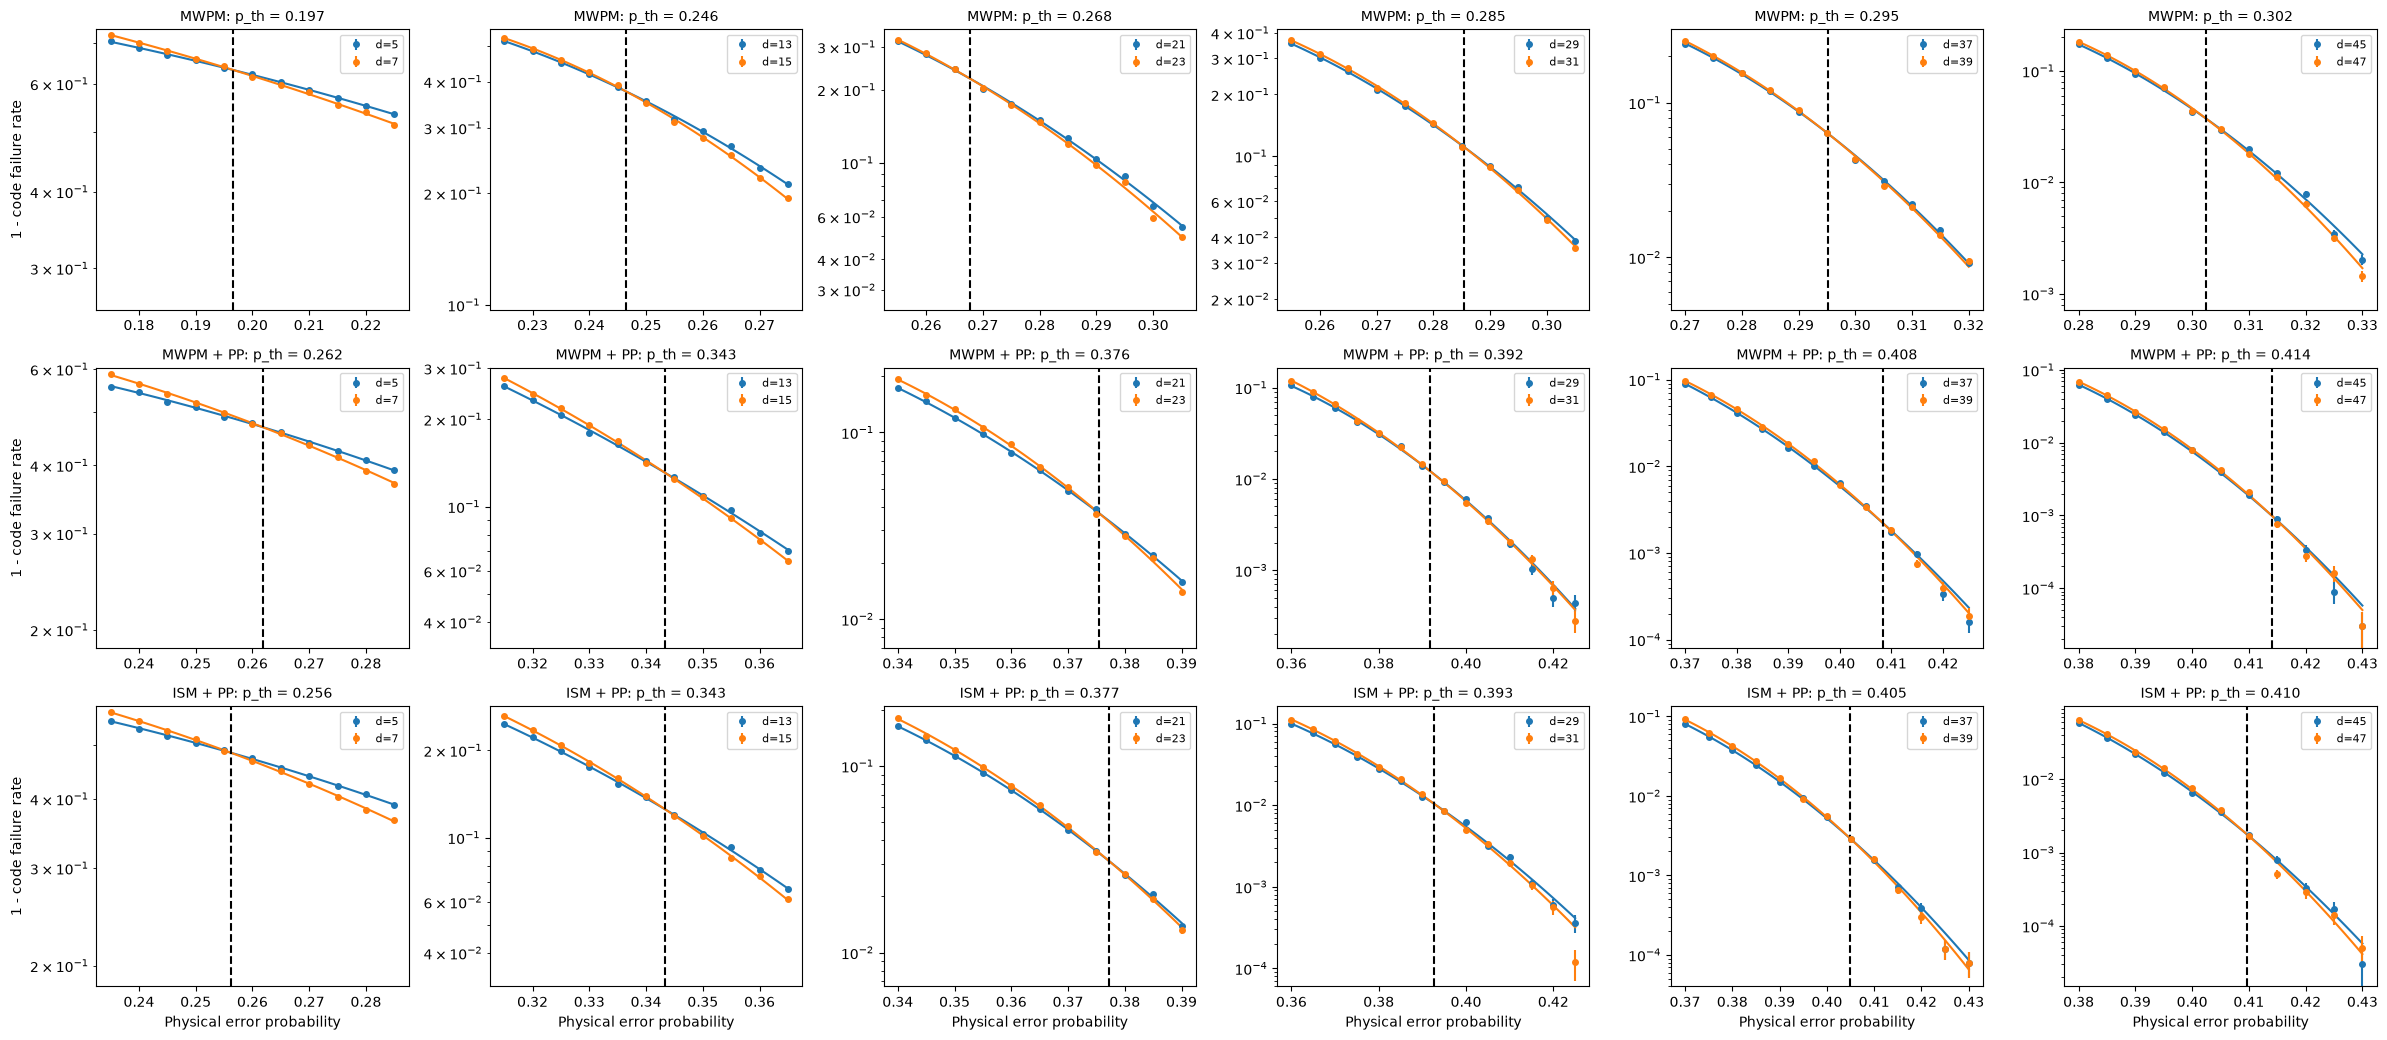

In [5]:
fig, axes = plt.subplots(len(DECODERS), len(PAIRS), figsize=(4 * len(PAIRS), 3.5 * len(DECODERS)))
for row, decoder in zip(axes, DECODERS):
    df = data[decoder]
    for ax, (d_small, d_large) in zip(row, PAIRS):
        for d in (d_small, d_large):
            curve = df[df["distance"] == d].sort_values("p_phys")
            s = 1 - curve["p_log"]
            line = ax.errorbar(curve["p_phys"], s, yerr=np.sqrt(s * (1 - s) / curve["num_shots"]),
                               fmt="o", markersize=4, label=f"d={d}")
            fit, lo, hi = fit_log_success(curve)
            p = np.linspace(lo, hi, 100)
            ax.plot(p, np.exp(fit(p)), color=line[0].get_color())
        t = thresholds[(thresholds["decoder"] == decoder) & (thresholds["d"] == d_small)].iloc[0]
        ax.axvline(t["p_th"], color="black", linestyle="dashed")
        ax.set_yscale("log")
        pair = df[df["distance"].isin([d_small, d_large])]
        ax.set_ylim(bottom=0.5 * (1 - pair["p_log"])[pair["p_log"] < 1].min())
        ax.set_title(f"{DECODERS[decoder]}: p_th = {t['p_th']:.3f}", fontsize=10)
        ax.legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Physical error probability")
for ax in axes[:, 0]:
    ax.set_ylabel("1 - code failure rate")
fig.tight_layout()
plt.show()

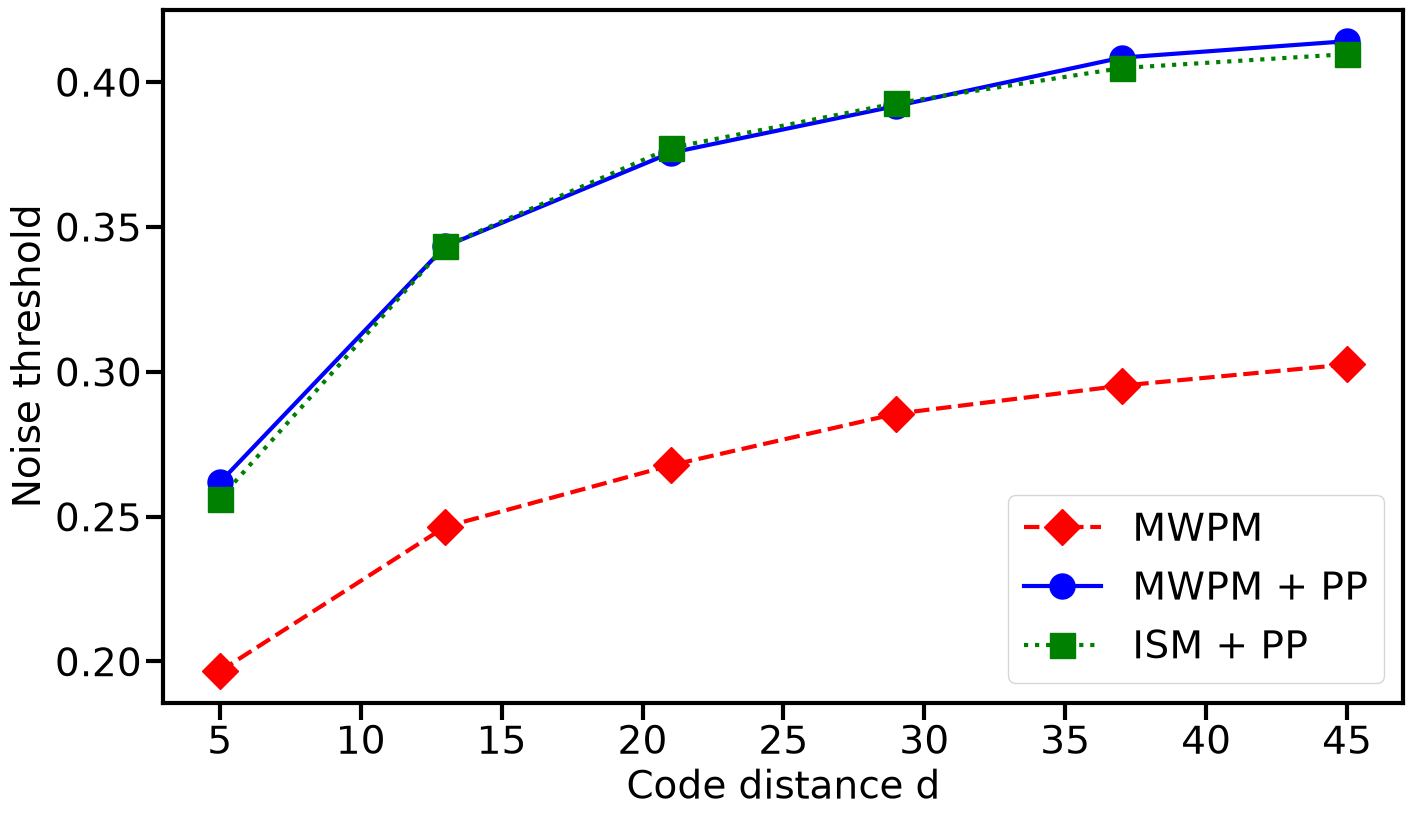

In [6]:
STYLES = {
    "MWPM + PP": dict(color='blue',    linestyle='solid',   marker='o', markersize=18),
    "MWPM":      dict(color='red',     linestyle='dashed',  marker='D', markersize=18),
    "ISM + PP": dict(color='green',   linestyle='dotted',  marker='s', markersize=18),
}

def plot_thresholds(thresholds, ax, save_path=None):
    for decoder, label in DECODERS.items():
        t = thresholds[thresholds["decoder"] == decoder]
        ax.plot(t["d"], t["p_th"], label=label, linewidth=3, **STYLES[label])
    ax.legend(loc="lower right", prop={"size": 28})
    # ax.set_xticks([d for d, _ in PAIRS])
    ax.tick_params(axis="both", labelsize=28)
    ax.set_xlabel("Code distance d", size=28)
    ax.set_ylabel("Noise threshold", size=28)
    # Thicker box around plot (spines)
    for spine in ax.spines.values():
        spine.set_linewidth(3)
    # Thicker major and minor ticks
    ax.tick_params(axis="both", which="major", width=3, length=12)
    ax.tick_params(axis="both", which="minor", width=1.5, length=8)
    if save_path is not None:
        ax.figure.savefig(save_path, format="pdf", bbox_inches="tight")
    plt.show()


fig, ax = plt.subplots(figsize=(16, 9))
plot_thresholds(thresholds, ax, save_path='./Fig-6-new.pdf')